In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
# ========================================
# 28-Class Fish Classification (AlexNet-style CNN)
# ========================================

import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# -----------------------------
# Paths & Parameters
# -----------------------------
IMG_HEIGHT, IMG_WIDTH = 227, 227
BATCH_SIZE = 128
EPOCHS = 10

TRAIN_DIR = "/kaggle/input/split-dataset-of-fish/split dataset of fish/train"
VAL_DIR   = "/kaggle/input/split-dataset-of-fish/split dataset of fish/val"
TEST_DIR  = "/kaggle/input/split-dataset-of-fish/split dataset of fish/test"

NUM_CLASSES = 28  # your fish dataset classes

# -----------------------------
# Data Generators
# -----------------------------
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# -----------------------------
# AlexNet-style CNN Model
# -----------------------------
model = Sequential([
    # Conv Layer 1
    Conv2D(96, (11,11), strides=4, activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH,3)),
    MaxPooling2D(pool_size=(3,3), strides=2),
    BatchNormalization(),

    # Conv Layer 2
    Conv2D(256, (5,5), padding='same', activation='relu'),
    MaxPooling2D(pool_size=(3,3), strides=2),
    BatchNormalization(),

    # Conv Layer 3
    Conv2D(384, (3,3), padding='same', activation='relu'),
    
    # Conv Layer 4
    Conv2D(256, (3,3), padding='same', activation='relu'),
    MaxPooling2D(pool_size=(3,3), strides=2),
    BatchNormalization(),

    # Flatten and Fully Connected
    Flatten(),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')  # 28-class output
])

# -----------------------------
# Compile Model
# -----------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# -----------------------------
# Callbacks
# -----------------------------
checkpoint = ModelCheckpoint(
    "best_fish_model.h5",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

earlystop = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# -----------------------------
# Train Model
# -----------------------------
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[checkpoint, earlystop]
)

# -----------------------------
# Evaluate on Test Set
# -----------------------------
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc*100:.2f}%")

# -----------------------------
# Save TFLite Model (Optional)
# -----------------------------
tflite_model_path = "fish_model.tflite"
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print("TFLite model saved:", tflite_model_path)


Found 58800 images belonging to 28 classes.
Found 8400 images belonging to 28 classes.
Found 16800 images belonging to 28 classes.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 27, 27, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 13, 13, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 28)             │       114,716 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,071,004 (217.71 MB)

 Trainable params: 57,069,788 (217.70 MB)

 Non-trainable params: 1,216 (4.75 KB)

... (4 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmpuugli1p2/assets


Saved artifact at '/tmp/tmpuugli1p2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 227, 227, 3), dtype=tf.float32, name='keras_tensor_31')
Output Type:
  TensorSpec(shape=(None, 28), dtype=tf.float32, name=None)
Captures:
  135432735110928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135432735112848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135432735112080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135432735111888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135432735111120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135432735112272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135428734304528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135428734306064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135428734306256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135428734304912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1354287343

W0000 00:00:1762713978.891305      48 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1762713978.891344      48 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1762713978.904968      48 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


TFLite model saved: fish_model.tflite


 60/132 ━━━━━━━━━━━━━━━━━━━━ 1:06 921ms/step

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


 63/132 ━━━━━━━━━━━━━━━━━━━━ 1:17 1s/step  

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (92415825 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


111/132 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (96378672 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


132/132 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step

📊 Classification Report:
               precision    recall  f1-score   support

         Aair     1.0000    0.0900    0.1651       600
    Black Roi     0.8739    0.8317    0.8523       600
         Boal     0.4487    0.0583    0.1032       600
      Chapila     0.7361    0.0883    0.1577       600
  Common Carp     0.8037    0.8050    0.8043       600
    DeshiPuti     1.0000    0.0083    0.0165       600
         Foli     0.1752    0.9950    0.2979       600
   Grass Carp     1.0000    0.3550    0.5240       600
        Ilish     0.7377    0.0750    0.1362       600
     KalBaush     0.9904    0.5167    0.6791       600
        Katla     0.5906    0.5050    0.5445       600
          Koi     1.0000    0.2133    0.3516       600
        Magur     0.0000    0.0000    0.0000       600
  Mirror Carp     0.6323    0.9800    0.7686       600
       Mrigel     1.0000    0.0317    0.0614       600
Nile Telapiya     0.9898    0.8067    0.8889       

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


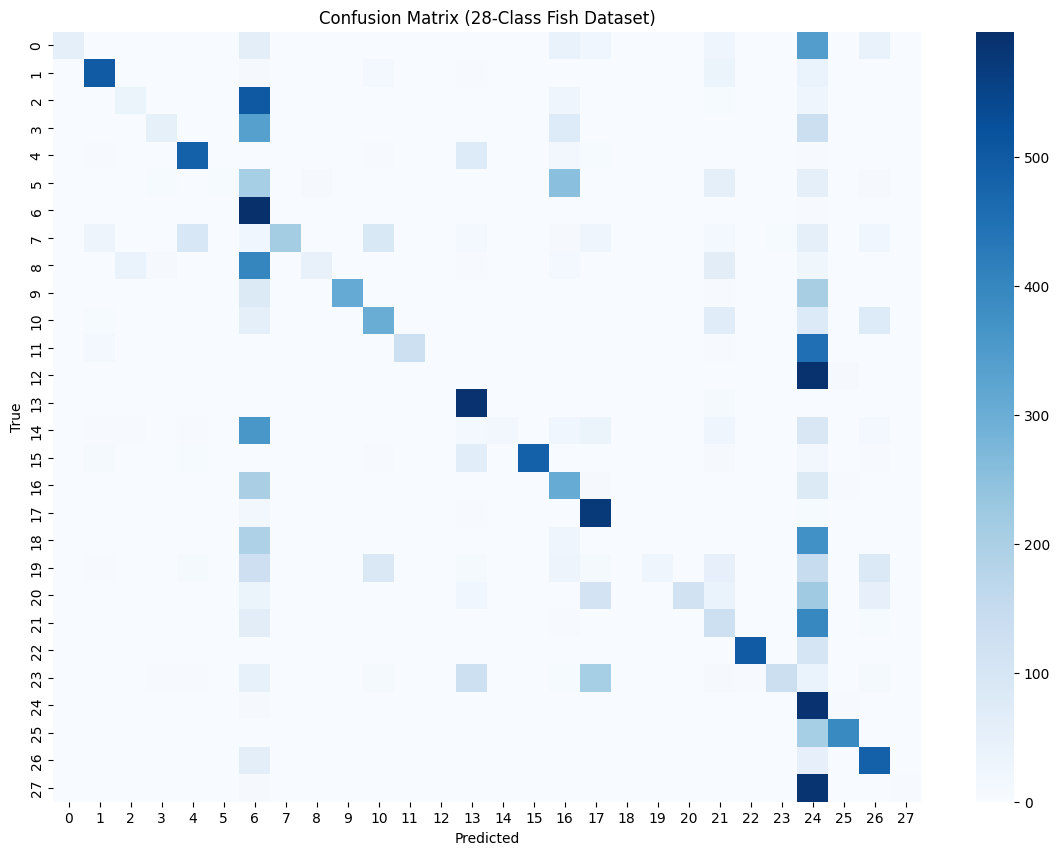


✅ Cohen's Kappa Score: 0.3988
✅ Overall Test Accuracy (manual check): 42.02%


In [4]:
# ==========================================
# Detailed Evaluation: Accuracy, Report, Kappa
# ==========================================
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Predict on test data
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

# Step 2: True labels
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Step 3: Classification Report
print("\n📊 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=4))

# Step 4: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=False, cmap='Blues', fmt='g')
plt.title("Confusion Matrix (28-Class Fish Dataset)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Step 5: Cohen’s Kappa
kappa = cohen_kappa_score(y_true, y_pred)
print(f"\n✅ Cohen's Kappa Score: {kappa:.4f}")

# Step 6: Overall Accuracy (double-check)
acc = np.mean(y_true == y_pred)
print(f"✅ Overall Test Accuracy (manual check): {acc*100:.2f}%")
